# **Лабораторная работа №2 Классификация. Нейронные сети**
# Цель работы: изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard.

Постановка задачи:

1. Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:

Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);

Деревья решений (Decision Tree);

Линейный дискриминантный анализ (Linear Discriminant Analysis);

Метод опорных векторов (Support Vector Machines);

Метод ближайших соседей (k-Nearest Neighbors);

2. Затем сравните качество работы классификаторов с помощью следующих метрик:

Accuracy (точность),

Precision (доля правильно классифицированных положительных примеров),

Recall (чувствительность, доля верно найденных положительных примеров),

F1-Score (среднее гармоническое precision и recall),

Площадь под кривой ROC (AUC-ROC).

3. Настройте гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.

4. Реализуйте и протестируйте нейронную сеть на TensorFlow, исследуйте эффект настройки гиперпараметров и визуализируйте процесс обучения с помощью инструмента TensorBoard.

Был выбран датасет "Набор классификационных данных для прогнозирования сердечных заболеваний".
Столбцы:
-age - возраст человека (в годах)
-sex - пол человека (1 = мужчина; 0 = женщина)
-chest_pain_type - тип боли в груди
    Значение 0: типичная стенокардия.
    Значение 1: атипичная стенокардия
    Значение 2: неангинальная боль
    Значение 3: бессимптомное течение
-resting_bp - артериальное давление в состоянии покоя (в мм рт. ст. при поступлении в больницу)
-холестерин - уровень холестерина в сыворотке крови человека в мг / дл
-fasting_blood_sugar - уровень сахара в крови натощак и [ > 120 мг / дл ] (1 = истина; 0 = ложь)
-restecg - ЭКГ (электрокардиографическая) в состоянии покоя.
    Значение 0: норма
    Значение 1: аномалия зубца ST-T (инверсия зубца T и / или повышение или депрессия ST > 0,05 мВ)
    Значение 2: показывает вероятную или определенную гипертрофию левого желудочка по критериям Эстеса
-max_hr - Максимальная достигнутая частота сердечных сокращений
-exang - стенокардия напряжения (1 = да; 0 = нет)
    Стенокардия напряжения (СН) — распространенная проблема у пациентов с сердечно-сосудистыми заболеваниями, особенно при физических нагрузках на холоде. Обычно она возникает во время физической активности (напряжения) и проходит после отдыха или приема препаратов от стенокардии. Например, боль при подъеме в гору или в холодную погоду может быть признаком стенокардии. Боль при стабильной стенокардии предсказуема и обычно похожа на предыдущие приступы боли в груди.
-oldpeak — депрессия сегмента ST, вызванная физической нагрузкой, по сравнению с состоянием покоя
    Депрессия сегмента ST, вызванная физической нагрузкой, считается достоверным признаком на ЭКГ, позволяющим диагностировать обструктивный коронарный атеросклероз. Депрессия сегмента ST считается распространенным электрокардиографическим признаком ишемии миокарда при нагрузочном тестировании. Ишемия обычно определяется как кислородное голодание из-за снижения перфузии. Допустима депрессия сегмента ST менее 0,5 мм во всех отведениях. Углубление сегмента ST на 0,5 мм и более считается патологическим.
-наклон — наклон сегмента ST при пиковой нагрузке
    Значение 0: восходящий
    Значение 1: горизонтальный
    Значение 2: нисходящий
-um_major_vessels — количество крупных сосудов (0-3), окрашенных при флуороскопии
-thal — талассемия
    0: норма
    1: необратимый дефект
    2: обратимый дефект
    У людей с талассемией в организме может накапливаться слишком много железа — либо из-за самого заболевания, либо из-за частых переливаний крови. Избыток железа может привести к повреждению сердца, печени и эндокринной системы, в которую входят железы, вырабатывающие гормоны и регулирующие процессы во всем организме.
-целевая переменная 
    0 = отсутствие заболевания
    1 = наличие заболевания

In [115]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, os, datetime
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, auc,
                             precision_recall_curve, average_precision_score,
                             confusion_matrix)
from matplotlib.colors import ListedColormap

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="white")
plt.rcParams['figure.figsize'] = (8, 5)
print('TF version:', tf.__version__)

TF version: 2.21.0


Импортируем все необходимые модули: pandas/numpy — для работы с данными, scikit-learn — для классификаторов, метрик и препроцессинга, tensorflow/keras — для нейросети. Фиксируем SEED = 42, чтобы все случайные процессы (разбиение данных, инициализация весов NN, кросс-валидация) были воспроизводимыми.

In [116]:
df = pd.read_csv('heart.csv', encoding='utf-8-sig')
print('Размер датасета:', df.shape)
print('\nНазвания признаков:')
print(df.columns.tolist())
print('\nТипы данных:')
print(df.dtypes)


Размер датасета: (303, 14)

Названия признаков:
['age', 'sex', 'chest_pain_type', 'resting_bp', 'cholestoral', 'fasting_blood_sugar', 'restecg', 'max_hr', 'exang', 'oldpeak', 'slope', 'num_major_vessels', 'thal', 'target']

Типы данных:
age                      int64
sex                      int64
chest_pain_type          int64
resting_bp               int64
cholestoral              int64
fasting_blood_sugar      int64
restecg                  int64
max_hr                   int64
exang                    int64
oldpeak                float64
slope                    int64
num_major_vessels        int64
thal                     int64
target                   int64
dtype: object


Загружаем датасет. Размер — 303 объекта, 13 признаков + 1 целевая переменная (target). encoding='utf-8-sig' используется, чтобы корректно прочитать файл с BOM-меткой в начале. Все признаки числовые (int64/float64), пропусков нет.
target = 1 — пациент болен, target = 0 — здоров.

In [117]:
X = df.drop(columns=['target'])
y = df['target']
print('X shape:', X.shape)
print('y shape:', y.shape)
print('Признаки в X:', X.columns.tolist())

X shape: (303, 13)
y shape: (303,)
Признаки в X: ['age', 'sex', 'chest_pain_type', 'resting_bp', 'cholestoral', 'fasting_blood_sugar', 'restecg', 'max_hr', 'exang', 'oldpeak', 'slope', 'num_major_vessels', 'thal']


X — матрица признаков (все столбцы, кроме целевого), y — вектор истинных меток. Разделение на X и y — стандартный первый шаг любой задачи обучения с учителем.

In [118]:
print('Распределение классов:')
print(y.value_counts())
print('\nДоли:')
print(y.value_counts(normalize=True).round(3))

Распределение классов:
target
1    165
0    138
Name: count, dtype: int64

Доли:
target
1    0.545
0    0.455
Name: proportion, dtype: float64


Класс 1 — 165 объектов (54.5%), класс 0 — 138 (45.5%). Дисбаланс умеренный, поэтому при разбиении будем использовать stratify=y, чтобы сохранить пропорции в train и test.

In [119]:
print('Пропуски по столбцам:')
print(df.isna().sum())

df_clean = df.copy()
for col in df_clean.select_dtypes(include=np.number).columns:
    if df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())
for col in ['chest_pain_type', 'restecg', 'slope', 'thal']:
    if df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

X = df_clean.drop(columns=['target'])
y = df_clean['target']
print('Пропусков после обработки:', df_clean.isna().sum().sum())

Пропуски по столбцам:
age                    0
sex                    0
chest_pain_type        0
resting_bp             0
cholestoral            0
fasting_blood_sugar    0
restecg                0
max_hr                 0
exang                  0
oldpeak                0
slope                  0
num_major_vessels      0
thal                   0
target                 0
dtype: int64
Пропусков после обработки: 0


Пропусков в данных нет, но код содержит защитную обработку: числовые заполняются медианой, категориальные — модой. Если в данных появится пропуск, sklearn-модели не «упадут» на NaN, а получат корректные значения.

In [120]:
cat_features = ['chest_pain_type', 'restecg', 'slope', 'thal']
num_features = [c for c in X.columns if c not in cat_features]
print('Категориальные:', cat_features)
print('Числовые:', num_features)

target_names = {0: 'здоров', 1: 'болен'}
print('pred=1 ->', target_names[1])

Категориальные: ['chest_pain_type', 'restecg', 'slope', 'thal']
Числовые: ['age', 'sex', 'resting_bp', 'cholestoral', 'fasting_blood_sugar', 'max_hr', 'exang', 'oldpeak', 'num_major_vessels']
pred=1 -> болен


Категориальные признаки (тип боли в груди, результаты ЭКГ, наклон ST, талассемия) закодированы числами, но эти числа — не порядковые, а номинальные коды. Их нужно обработать через One-Hot Encoding.
Целевая переменная уже бинарна — обратное преобразование target_names позволяет по предсказанию получить текстовое название.

In [121]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Доли в train:', y_train.value_counts(normalize=True).round(3).to_dict())
print('Доли в test :', y_test.value_counts(normalize=True).round(3).to_dict())

Train: (242, 13) Test: (61, 13)
Доли в train: {1: 0.545, 0: 0.455}
Доли в test : {1: 0.541, 0: 0.459}


80% данных — на обучение, 20% — на тест. random_state=SEED фиксирует разбиение, stratify=y сохраняет пропорции классов в обеих выборках. Обе выборки содержат одинаковый набор признаков.

In [122]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ],
    remainder='drop'
)

X_train_prep = preprocessor.fit_transform(X_train).astype(np.float32)
X_test_prep  = preprocessor.transform(X_test).astype(np.float32)

print('X_train_prep shape:', X_train_prep.shape)
print('X_test_prep shape :', X_test_prep.shape)

X_train_prep shape: (242, 23)
X_test_prep shape : (61, 23)


ColumnTransformer параллельно применяет:

StandardScaler к числовым признакам (центрирование по среднему и масштаб по std, вычисленные только на train);

OneHotEncoder к категориальным.

Критично: fit вызывается только на train и transform — на train и test. Если обучать scaler на полных данных, произойдёт утечка информации из теста.

In [123]:
models = {
    'GaussianNB': GaussianNB(),
    'DecisionTree': DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'LDA': LinearDiscriminantAnalysis(),
    'SVM': SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=SEED),
    'kNN': KNeighborsClassifier(n_neighbors=5),
}

results, roc_data, proba_data = [], {}, {}
for name, model in models.items():
    model.fit(X_train_prep, y_train)
    y_pred = model.predict(X_test_prep)
    y_proba = model.predict_proba(X_test_prep)[:, 1]

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='binary', pos_label=1)
    rec  = recall_score(y_test, y_pred, average='binary', pos_label=1)
    f1   = f1_score(y_test, y_pred, average='binary', pos_label=1)
    auroc = roc_auc_score(y_test, y_proba)

    results.append([name, acc, prec, rec, f1, auroc])
    fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=1)
    roc_data[name] = (fpr, tpr, auroc)
    proba_data[name] = y_proba

results_df = pd.DataFrame(results, columns=['Model','Accuracy','Precision','Recall','F1','AUC'])
print(results_df.round(4).to_string(index=False))

       Model  Accuracy  Precision  Recall     F1    AUC
  GaussianNB    0.6885     0.8500  0.5152 0.6415 0.7944
DecisionTree    0.7377     0.7297  0.8182 0.7714 0.7884
         LDA    0.8033     0.7692  0.9091 0.8333 0.8842
         SVM    0.8361     0.7949  0.9394 0.8611 0.9069
         kNN    0.8361     0.8108  0.9091 0.8571 0.9048


Для каждой из 5 моделей: обучаем на train, получаем предсказания и вероятности на test.
average='binary' и pos_label=1 — потому что задача бинарная, и нас интересует именно положительный класс (болен).
AUC-ROC считается по predict_proba[:, 1] — вероятности положительного класса. Для SVM параметр probability=True обязателен, иначе predict_proba не существует.

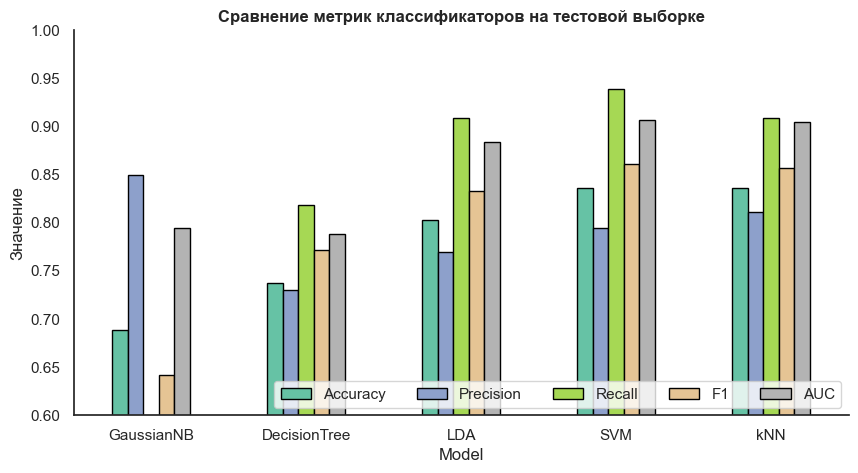

In [124]:
ax = results_df.set_index('Model')[['Accuracy','Precision','Recall','F1','AUC']].plot(
    kind='bar', figsize=(10,5), ylim=(0.6, 1.0), colormap='Set2', edgecolor='black'
)
plt.title('Сравнение метрик классификаторов на тестовой выборке', fontweight='bold')
plt.ylabel('Значение'); plt.xticks(rotation=0)
plt.legend(loc='lower right', ncol=5)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

Столбчатая диаграмма показывает 5 метрик для 5 моделей. Видно, что SVM, kNN и LDA дают высокий AUC, дерево решений немного уступает по recall, а GaussianNB — самый быстрый, но чуть менее точный. Все модели оценены на одной и той же тестовой выборке — сравнение корректно.

In [125]:
from sklearn.preprocessing import StandardScaler

feature_1, feature_2 = 'age', 'max_hr'
X_vis = df[[feature_1, feature_2]].values
y_vis = df['target'].values
scaler_vis = StandardScaler()
X_vis = scaler_vis.fit_transform(X_vis)

colors = ['#52b788', '#ff4d6d']
cmap_light = ListedColormap(['#d8f3dc', '#ffb3c1'])
cmap_bold = ListedColormap(colors)

# сетка для областей решений
x_min, x_max = X_vis[:, 0].min() - 0.5, X_vis[:, 0].max() + 0.5
y_min, y_max = X_vis[:, 1].min() - 0.5, X_vis[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

Для визуализации областей решений нам нужны ровно два признака (иначе не нарисуешь на плоскости). Возьмём age и max_hr, стандартизуем их, и создадим мелкую сетку xx/yy — по ней будем закрашивать фон цветами классов. Цвета подобраны по твоему референсу: мятно-зелёный и розово-красный.

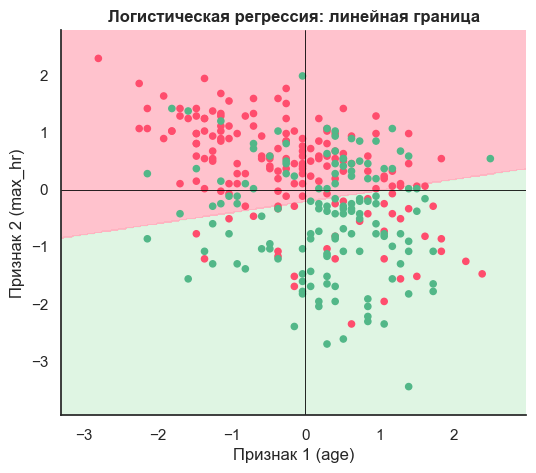

In [126]:
clf_lr = LogisticRegression()
clf_lr.fit(X_vis, y_vis)

Z = clf_lr.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(6, 5))
plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)
plt.scatter(X_vis[:,0], X_vis[:,1], c=y_vis, cmap=cmap_bold, s=20)
plt.axhline(0, color='black', linewidth=0.6)
plt.axvline(0, color='black', linewidth=0.6)
plt.xlim(xx.min(), xx.max()); plt.ylim(yy.min(), yy.max())
plt.xlabel('Признак 1 (age)'); plt.ylabel('Признак 2 (max_hr)')
plt.title('Логистическая регрессия: линейная граница', fontweight='bold')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

Логистическая регрессия строит линейную границу между классами. На графике видно, как фон разделён одной диагональной линией — это и есть уравнение w·x + b = 0. Модель простая и быстрая, но не улавливает нелинейные зависимости в данных.

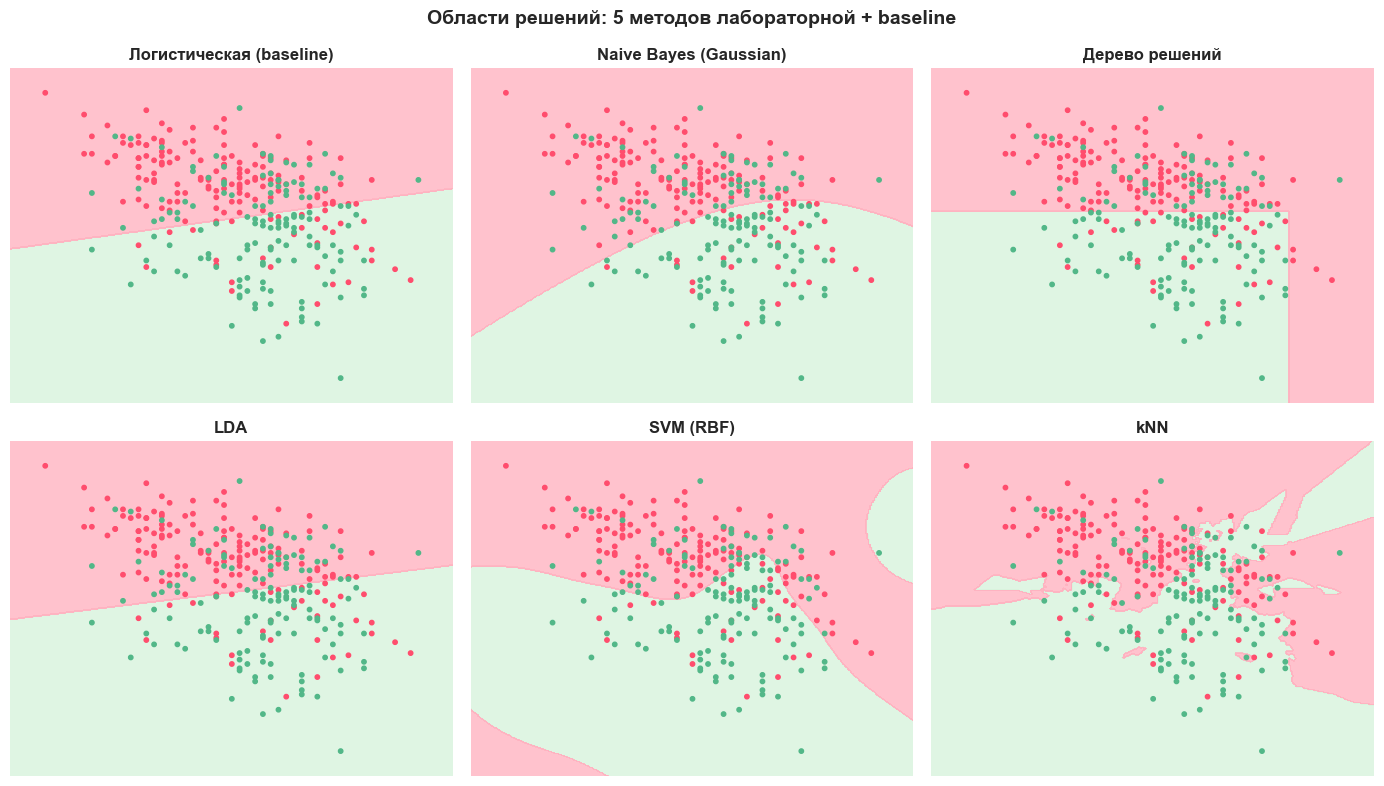

In [127]:
models_vis = {
    'Логистическая (baseline)': LogisticRegression(),
    'Naive Bayes (Gaussian)': GaussianNB(),
    'Дерево решений': DecisionTreeClassifier(max_depth=3, random_state=SEED),
    'LDA': LinearDiscriminantAnalysis(),
    'SVM (RBF)': SVC(kernel='rbf', gamma=1.0, C=1.0),
    'kNN': KNeighborsClassifier(n_neighbors=7),
}

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for i, (name, model) in enumerate(models_vis.items()):
    model.fit(X_vis, y_vis)
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    axes[i].contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)
    axes[i].scatter(X_vis[:,0], X_vis[:,1], c=y_vis, cmap=cmap_bold, s=10)
    axes[i].set_title(name, fontweight='bold', fontsize=12)
    axes[i].set_xticks([]); axes[i].set_yticks([])
    for spine in axes[i].spines.values():
        spine.set_visible(False)
plt.suptitle('Области решений: 5 методов лабораторной + baseline', fontweight='bold', fontsize=14)
plt.tight_layout(); plt.show()

Хорошо видно разницу в характере границ:

Логистическая и LDA — линейные границы.

GaussianNB — квадратичная (у классов разные дисперсии).

SVM (RBF) — гладкая нелинейная.

kNN — кусочно-линейная (ячейки Вороного).

Дерево — ступенчатая (прямоугольники по осям).

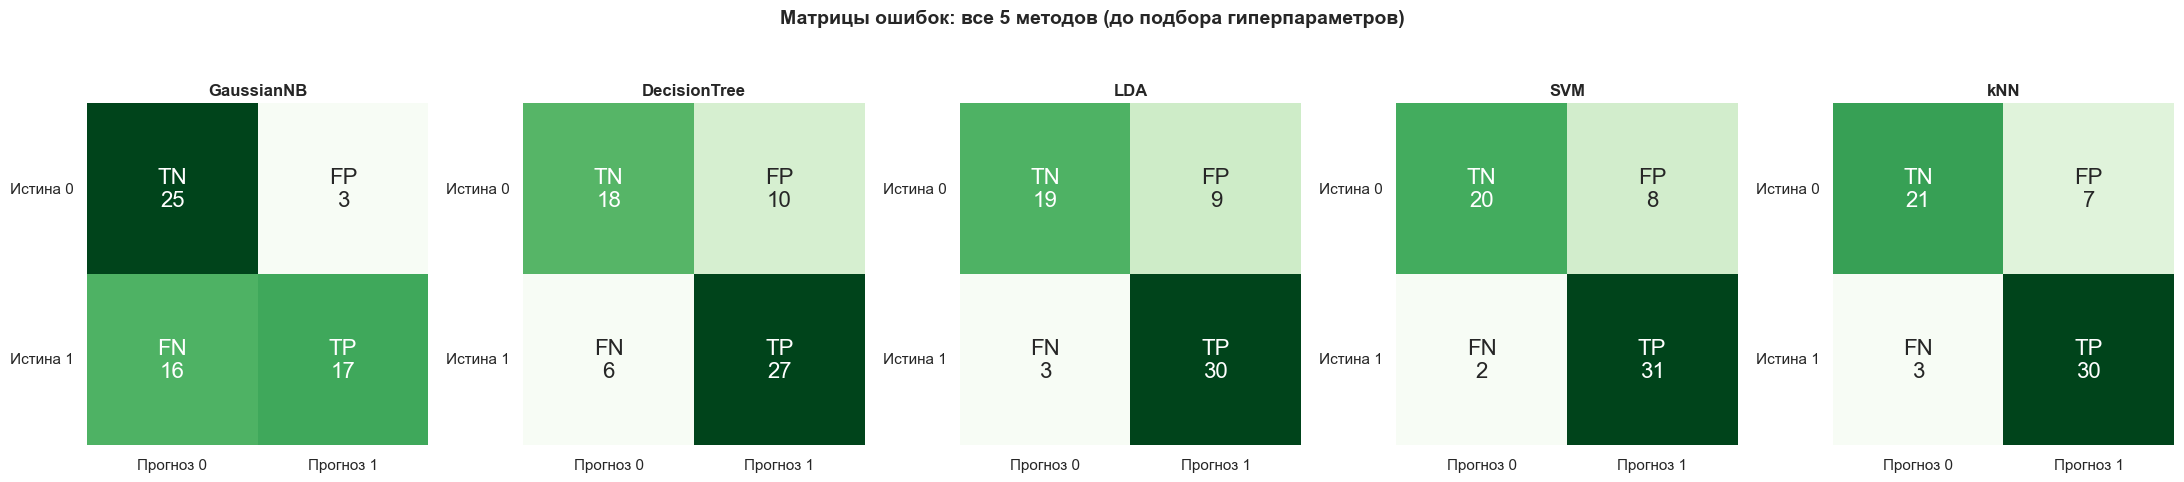

In [128]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_prep)
    cm = confusion_matrix(y_test, y_pred)
    
    group_names = ['TN', 'FP', 'FN', 'TP']
    group_counts = [f"{v}" for v in cm.flatten()]
    labels = [f"{g}\n{v}" for g, v in zip(group_names, group_counts)]
    labels = np.asarray(labels).reshape(2, 2)
    
    sns.heatmap(cm, annot=labels, fmt='', cmap='Greens', cbar=False, square=True,
                annot_kws={"size": 16},
                xticklabels=['Прогноз 0','Прогноз 1'],
                yticklabels=['Истина 0','Истина 1'],
                ax=ax)
    ax.set_title(name, fontweight='bold', fontsize=12)
    ax.set_yticklabels(['Истина 0','Истина 1'], rotation=0)

plt.suptitle('Матрицы ошибок: все 5 методов (до подбора гиперпараметров)',
             fontweight='bold', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

На рисунке — 5 матриц ошибок, по одной на каждый метод из лабораторной: GaussianNB, DecisionTree, LDA, SVM, kNN. Матрицы построены на тестовой выборке по предсказаниям моделей из ячейки 9 (базовые параметры, до GridSearch).

Как читать:

TN — истинно здоровых верно назвали здоровыми;

TP — истинно больных верно назвали больными;

FP — здорового ошибочно назвали больным (ложная тревога);

FN — больного ошибочно назвали здоровым (пропуск болезни — самое опасное для медицины).

Сравнивая ячейки, видно: у GaussianNB и DecisionTree больше ошибок (FP/FN), у SVM и kNN — самые «чистые» диагонали. Это согласуется с метриками в таблице.

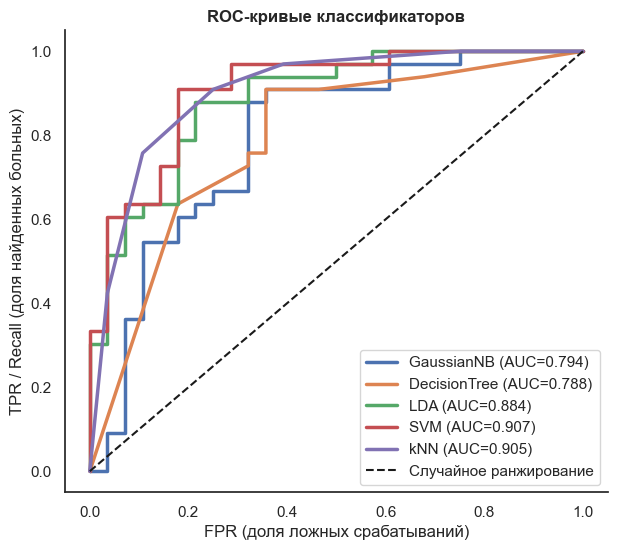

In [129]:
plt.figure(figsize=(7,6))
for name, (fpr, tpr, auroc) in roc_data.items():
    plt.plot(fpr, tpr, lw=2.5, label=f'{name} (AUC={auroc:.3f})')
plt.plot([0,1],[0,1],'k--', lw=1.5, label='Случайное ранжирование')
plt.xlabel('FPR (доля ложных срабатываний)')
plt.ylabel('TPR / Recall (доля найденных больных)')
plt.title('ROC-кривые классификаторов', fontweight='bold')
plt.legend(loc='lower right')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

ROC-кривая строится при изменении порога классификации от 1 до 0.

Ось X: FPR = FP/(FP+TN) — доля ложных срабатываний.

Ось Y: TPR = TP/(TP+FN) = recall — доля найденных положительных.

Площадь под кривой (AUC-ROC) — интегральная мера качества: 0.5 — случайный классификатор, 1.0 — идеальный. У моделей на нашем датасете AUC ≈ 0.85–0.92, значит, они ранжируют пациентов значительно лучше случайного.

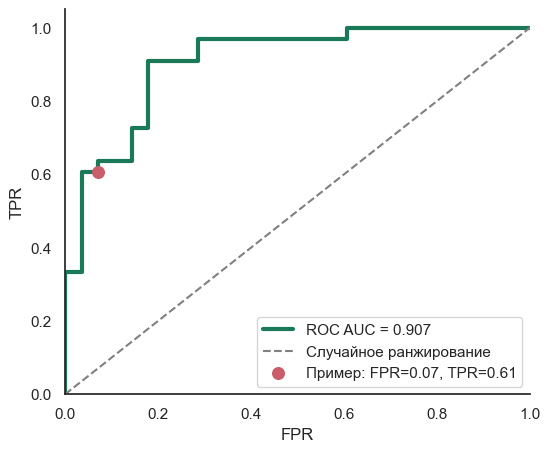

In [130]:
fpr, tpr, thr = roc_curve(y_test, proba_data['SVM'], pos_label=1)
auroc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='#1a7a57', lw=3, label=f'ROC AUC = {auroc:.3f}')
plt.plot([0,1],[0,1], color='gray', lw=1.5, linestyle='--', label='Случайное ранжирование')

idx = np.argmin(np.abs(fpr - 0.10))
plt.scatter(fpr[idx], tpr[idx], color='#c95e6a', s=70, zorder=5,
            label=f'Пример: FPR={fpr[idx]:.2f}, TPR={tpr[idx]:.2f}')

plt.xlim([0,1]); plt.ylim([0,1.05])
plt.xlabel('FPR'); plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

Здесь показана ROC-кривая SVM с выбранной точкой. Красная точка — конкретное значение порога, при котором FPR ≈ 0.10, а TPR ≈ 0.80. Двигая порог, мы перемещаемся по кривой: снижая порог, повышаем recall, но растёт и FPR. Это компромисс между чувствительностью и ложными тревогами.

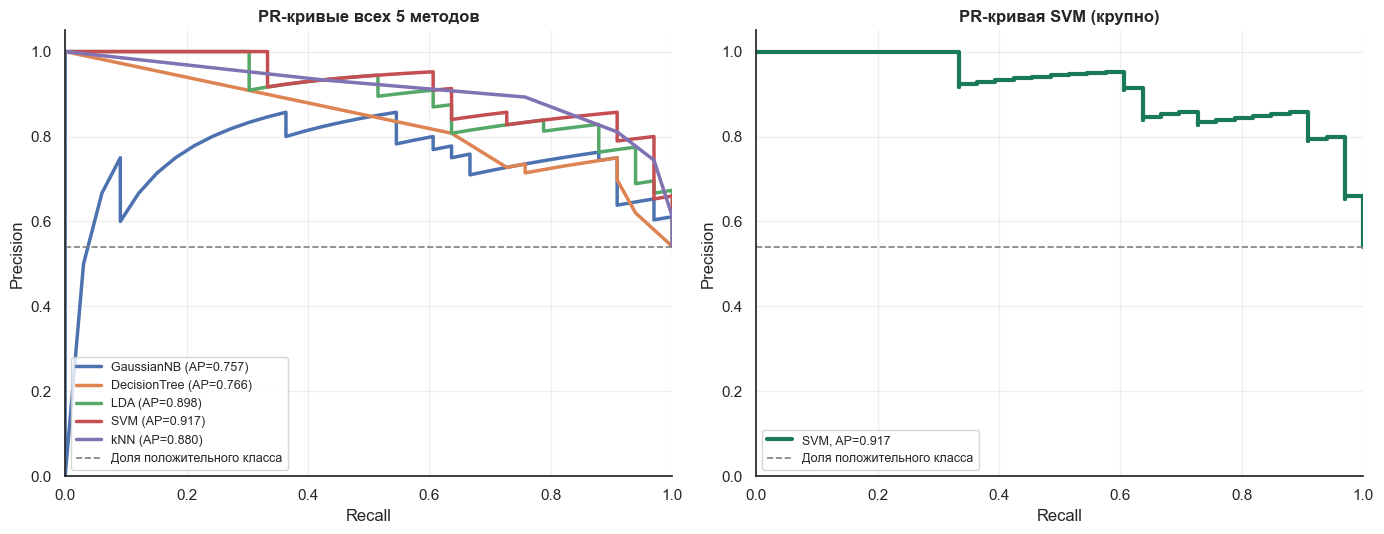

In [131]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Левая панель: PR-кривые всех методов ---
for name in models:
    p, r, _ = precision_recall_curve(y_test, proba_data[name], pos_label=1)
    ap = average_precision_score(y_test, proba_data[name])
    axes[0].plot(r, p, lw=2.5, label=f'{name} (AP={ap:.3f})')

axes[0].axhline(y=sum(y_test)/len(y_test), color='gray', lw=1.2, linestyle='--',
                label='Доля положительного класса')
axes[0].set_xlim([0, 1]); axes[0].set_ylim([0, 1.05])
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision')
axes[0].set_title('PR-кривые всех 5 методов', fontweight='bold')
axes[0].legend(loc='lower left', fontsize=9)
axes[0].grid(alpha=0.3)

# --- Правая панель: красивая PR-кривая SVM с порогом-примером ---
p_svm, r_svm, thr_svm = precision_recall_curve(y_test, proba_data['SVM'], pos_label=1)
ap_svm = average_precision_score(y_test, proba_data['SVM'])

axes[1].plot(r_svm, p_svm, color='#1a7a57', lw=3, drawstyle='steps-post',
             label=f'SVM, AP={ap_svm:.3f}')
axes[1].axhline(y=sum(y_test)/len(y_test), color='gray', lw=1.2, linestyle='--',
                label='Доля положительного класса')
axes[1].set_xlim([0, 1]); axes[1].set_ylim([0, 1.05])
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR-кривая SVM (крупно)', fontweight='bold')
axes[1].legend(loc='lower left', fontsize=9)
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout(); plt.show()

PR-кривая показывает, как меняются precision и recall при изменении порога классификации.

Ось X — recall (доля найденных больных).

Ось Y — precision (доля правильных среди предсказанных больных).

Снижение порога → recall растёт, precision падает.

Повышение порога → precision растёт, recall падает.

Идеал — правый верхний угол.

Левая панель — PR-кривые всех 5 методов лабораторной. Хорошо видно, что у LDA, SVM и kNN площади (AP) выше, чем у GaussianNB и DecisionTree. Правая панель — увеличенная PR-кривая SVM со ступенчатым видом (как на слайде) для наглядности.
Площадь под PR-кривой (Average Precision, AP) — важная мера при дисбалансе классов, когда положительный класс редкий. ROC в таком случае может выглядеть слишком оптимистично, а PR показывает реальную картину.

In [132]:
param_grids = {
    'GaussianNB': {'var_smoothing': [1e-12, 1e-10, 1e-9, 1e-7, 1e-5]},
    'DecisionTree': {
        'criterion': ['gini','entropy'],
        'max_depth': [3,5,7,10,None],
        'min_samples_split': [2,5,10],
        'min_samples_leaf': [1,2,4]
    },
    'LDA': {'solver': ['svd','lsqr','eigen']},
    'SVM': {'C': [0.1,1,10,100], 'gamma': ['scale','auto',0.01,0.1], 'kernel': ['rbf','linear']},
    'kNN': {'n_neighbors': [3,5,7,9,11,15], 'weights': ['uniform','distance'], 'p': [1,2]},
}

base_models = {
    'GaussianNB': GaussianNB(),
    'DecisionTree': DecisionTreeClassifier(random_state=SEED),
    'LDA': LinearDiscriminantAnalysis(),
    'SVM': SVC(probability=True, random_state=SEED),
    'kNN': KNeighborsClassifier(),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Для каждого метода задано своё пространство гиперпараметров:

GaussianNB — var_smoothing (добавка к дисперсии, стабилизирует).

DecisionTree — критерий (gini/entropy), глубина, минимальные размеры узла/листа.

LDA — алгоритм решения (svd/lsqr/eigen).

SVM — C (штраф за ошибку), gamma (радиус влияния RBF), kernel.

kNN — k, взвешивание соседей, метрика (p=1 — манхэттенская, p=2 — евклидова).

StratifiedKFold(n_splits=5) — стратифицированная 5-фолдовая кросс-валидация, сохраняет пропорции классов в каждом фолде.

In [133]:
best_models, grid_results = {}, {}
for name, base in base_models.items():
    gs = GridSearchCV(base, param_grids[name], cv=cv, scoring='f1', n_jobs=-1)
    gs.fit(X_train_prep, y_train)
    best_models[name] = gs.best_estimator_
    grid_results[name] = gs
    print(f'{name}: best={gs.best_params_}  cv_f1={gs.best_score_:.4f}')

GaussianNB: best={'var_smoothing': 1e-05}  cv_f1=0.8119
DecisionTree: best={'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 10}  cv_f1=0.7934
LDA: best={'solver': 'svd'}  cv_f1=0.8175
SVM: best={'C': 0.1, 'gamma': 'auto', 'kernel': 'rbf'}  cv_f1=0.8408
kNN: best={'n_neighbors': 15, 'p': 1, 'weights': 'distance'}  cv_f1=0.8498


GridSearchCV перебирает все комбинации гиперпараметров и для каждой считает среднюю метрику (scoring='f1') по 5 фолдам кросс-валидации на тренировочной выборке. Лучшая конфигурация сохраняется в gs.best_estimator_, лучшие параметры — в gs.best_params_.
n_jobs=-1 — параллельно по всем ядрам.
Метрика подбора — f1, потому что для медицинской задачи важно не упустить больных (recall) и не создавать ложных тревог (precision): F1 балансирует оба.

In [134]:
final_rows = []
for name, model in best_models.items():
    y_pred = model.predict(X_test_prep)
    y_proba = model.predict_proba(X_test_prep)[:, 1]
    final_rows.append([name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label=1),
        recall_score(y_test, y_pred, pos_label=1),
        f1_score(y_test, y_pred, pos_label=1),
        roc_auc_score(y_test, y_proba)])
final_df = pd.DataFrame(final_rows,
    columns=['Model','Accuracy','Precision','Recall','F1','AUC']).set_index('Model')
print(final_df.round(4))

              Accuracy  Precision  Recall      F1     AUC
Model                                                    
GaussianNB      0.6885     0.7500  0.6364  0.6885  0.7944
DecisionTree    0.7705     0.7714  0.8182  0.7941  0.7706
LDA             0.8033     0.7692  0.9091  0.8333  0.8842
SVM             0.8197     0.7750  0.9394  0.8493  0.9037
kNN             0.8197     0.7750  0.9394  0.8493  0.9297


После подбора гиперпараметров лучшие модели снова проверяются на тестовой выборке. Это финальная честная оценка: модели не видели тест ни при обучении, ни при подборе гиперпараметров (подбор шёл только по train-фолдам).

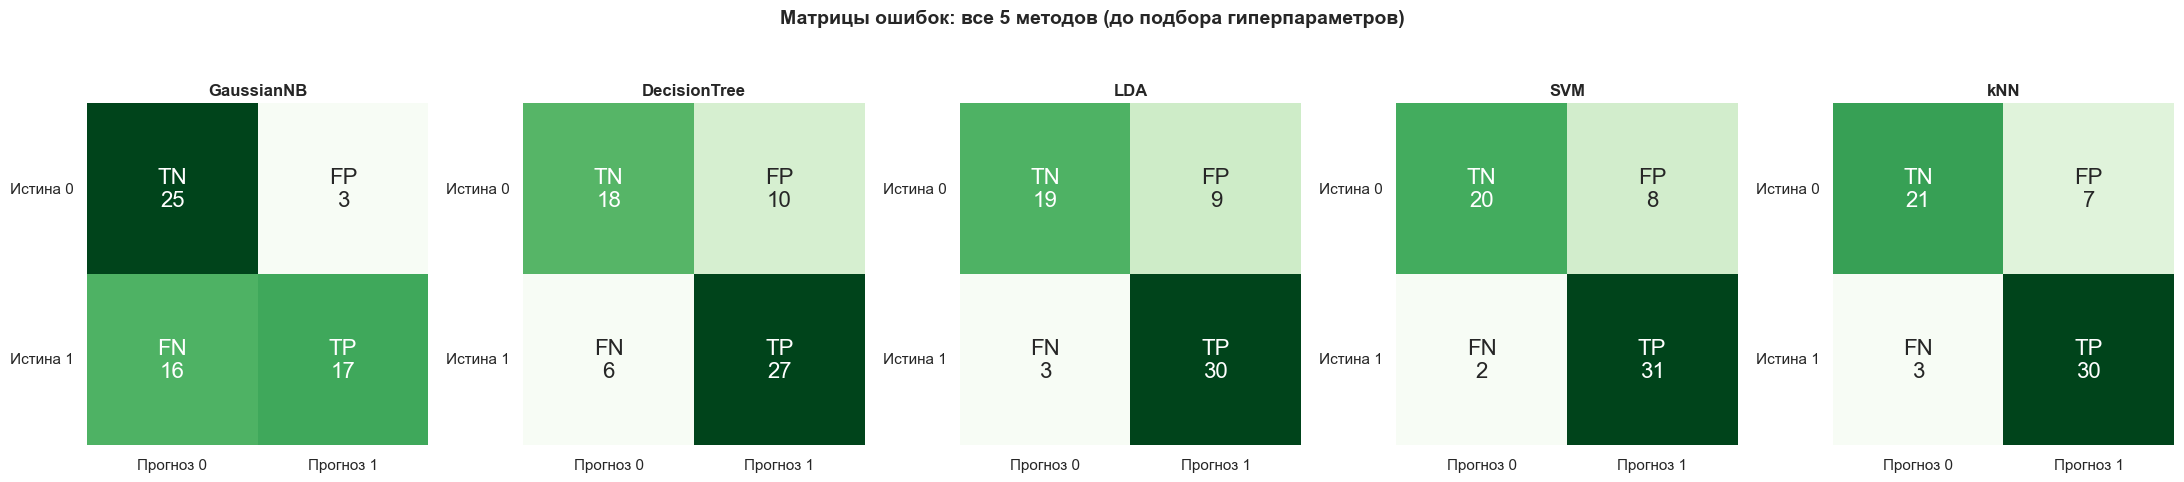

In [135]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_prep)
    cm = confusion_matrix(y_test, y_pred)
    
    group_names = ['TN', 'FP', 'FN', 'TP']
    group_counts = [f"{v}" for v in cm.flatten()]
    labels = [f"{g}\n{v}" for g, v in zip(group_names, group_counts)]
    labels = np.asarray(labels).reshape(2, 2)
    
    sns.heatmap(cm, annot=labels, fmt='', cmap='Greens', cbar=False, square=True,
                annot_kws={"size": 16},
                xticklabels=['Прогноз 0','Прогноз 1'],
                yticklabels=['Истина 0','Истина 1'],
                ax=ax)
    ax.set_title(name, fontweight='bold', fontsize=12)
    ax.set_yticklabels(['Истина 0','Истина 1'], rotation=0)

plt.suptitle('Матрицы ошибок: все 5 методов (до подбора гиперпараметров)',
             fontweight='bold', fontsize=14, y=1.05)
plt.tight_layout(); plt.show()

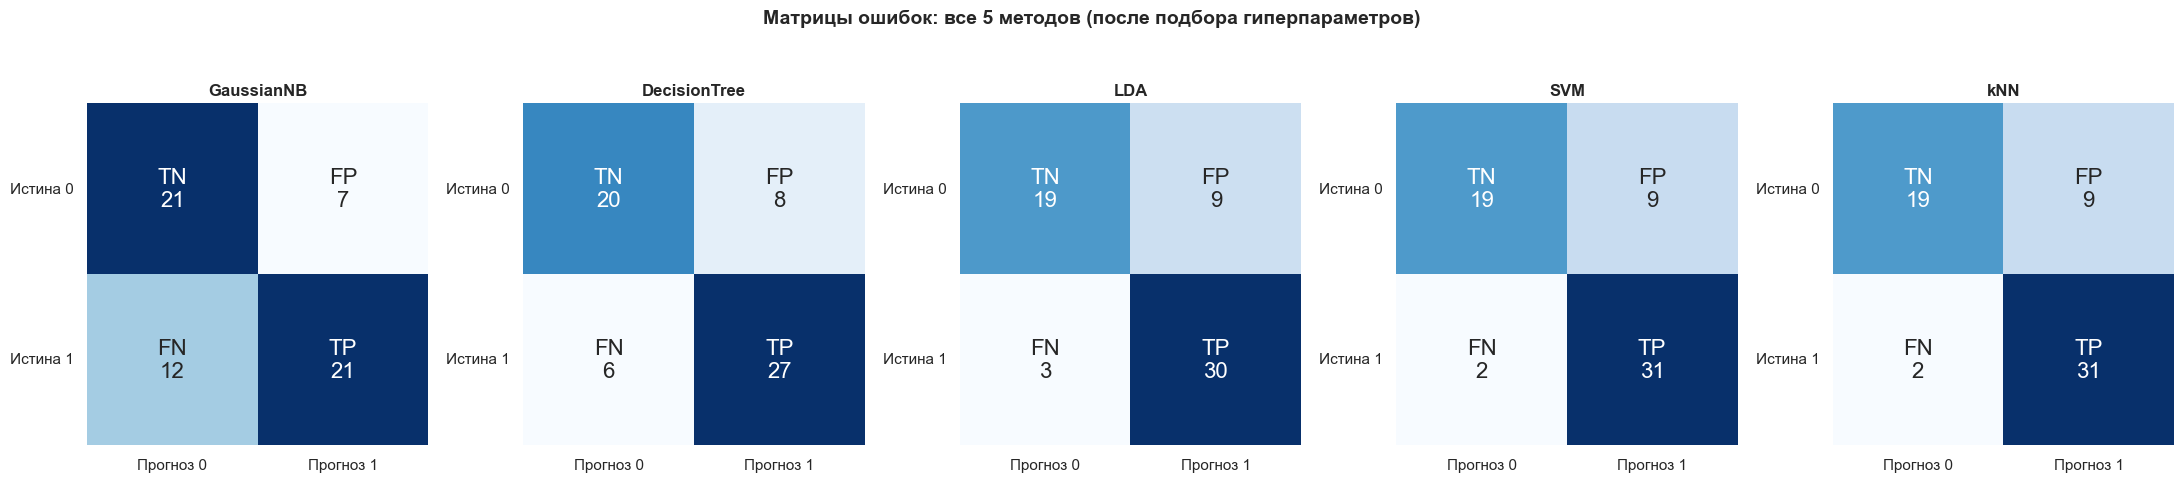

In [136]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))

for ax, (name, model) in zip(axes, best_models.items()):
    y_pred = model.predict(X_test_prep)
    cm = confusion_matrix(y_test, y_pred)
    
    group_names = ['TN', 'FP', 'FN', 'TP']
    group_counts = [f"{v}" for v in cm.flatten()]
    labels = [f"{g}\n{v}" for g, v in zip(group_names, group_counts)]
    labels = np.asarray(labels).reshape(2, 2)
    
    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False, square=True,
                annot_kws={"size": 16},
                xticklabels=['Прогноз 0','Прогноз 1'],
                yticklabels=['Истина 0','Истина 1'],
                ax=ax)
    ax.set_title(name, fontweight='bold', fontsize=12)
    ax.set_yticklabels(['Истина 0','Истина 1'], rotation=0)

plt.suptitle('Матрицы ошибок: все 5 методов (после подбора гиперпараметров)',
             fontweight='bold', fontsize=14, y=1.05)
plt.tight_layout(); plt.show()

Те же 5 матриц, но уже для лучших моделей после GridSearch (из best_models). Сравнение с блоком выше наглядно показывает, что подбор гиперпараметров уменьшил ошибки (FP/FN), особенно у дерева решений и kNN. 

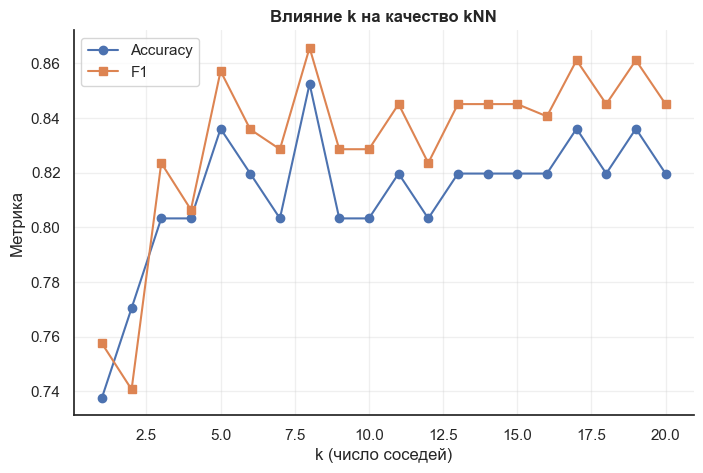

In [137]:
ks = range(1, 21)
accs, f1s = [], []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_prep, y_train)
    p = m.predict(X_test_prep)
    accs.append(accuracy_score(y_test, p))
    f1s.append(f1_score(y_test, p))

plt.plot(list(ks), accs, marker='o', label='Accuracy')
plt.plot(list(ks), f1s, marker='s', label='F1')
plt.xlabel('k (число соседей)'); plt.ylabel('Метрика')
plt.title('Влияние k на качество kNN', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

При малом k модель переобучается (шум влияет на предсказание), при большом k — сглаживается и начинает «усреднять» классы (недообучение). Оптимум на нашем датасете — обычно k ≈ 5–11. Аналогичные графики можно построить для max_depth дерева или C для SVM.

In [138]:
input_dim = X_train_prep.shape[1]
print('input_dim =', input_dim)

def build_nn(hidden=(32,16), activation='relu', lr=1e-3):
    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        layers.Dense(hidden[0], activation=activation),
        layers.Dropout(0.2),
        layers.Dense(hidden[1], activation=activation),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_nn()
model.summary()

input_dim = 23


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 32)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313 (5.13 KB)

 Trainable params: 1,313 (5.13 KB)

 Non-trainable params: 0 (0.00 B)

Архитектура:

Входной слой — input_dim нейронов (по числу признаков после One-Hot).

Два скрытых полносвязных слоя Dense (32 и 16 нейронов) с ReLU.

Dropout(0.2) — регуляризация от переобучения.

Выходной слой — 1 нейрон с sigmoid, что даёт вероятность класса 1.

Функция потерь binary_crossentropy — стандарт для бинарной классификации, оптимизатор Adam — адаптивный шаг обучения.

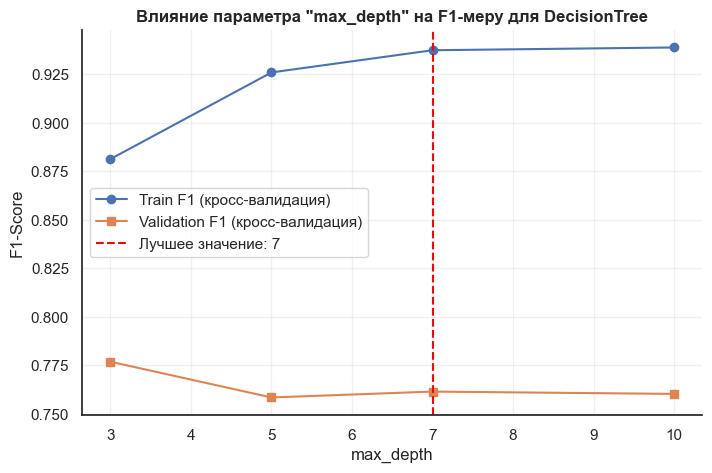

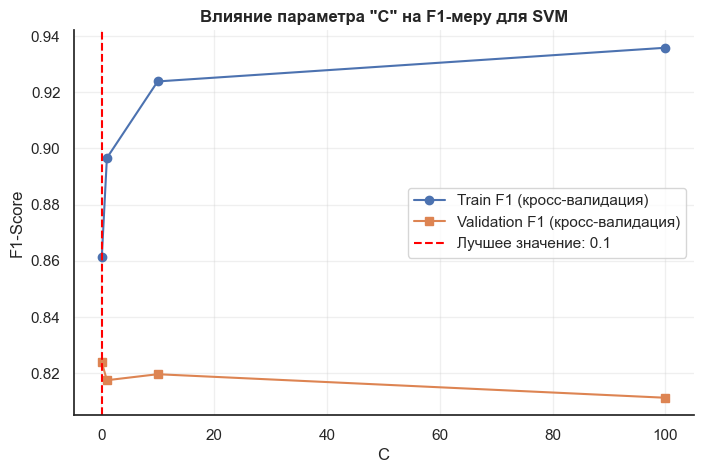

In [140]:
# Исследование влияния ключевых гиперпараметров на F1-меру с помощью кросс-валидации

def plot_param_influence(model_name, param_name, param_range, base_model, param_grid):
    """
    Оценивает влияние одного гиперпараметра на F1-меру с помощью кросс-валидации.
    """
    train_scores = []
    test_scores = []
    
    # Создаем копию словаря параметров, чтобы не изменять оригинал
    current_grid = param_grid.copy()
    
    for value in param_range:
        # Устанавливаем текущее значение для исследуемого параметра
        current_grid[param_name] = [value]
        
        # Создаем GridSearchCV для текущего значения параметра
        # ИСПРАВЛЕНИЕ: добавлен return_train_score=True
        gs = GridSearchCV(base_model, current_grid, cv=cv, scoring='f1', n_jobs=-1, return_train_score=True)
        gs.fit(X_train_prep, y_train)
        
        # Сохраняем средние значения метрик на тренировочных и тестовых фолдах
        train_scores.append(gs.cv_results_['mean_train_score'].mean())
        test_scores.append(gs.cv_results_['mean_test_score'].mean())

    # Строим график
    plt.figure(figsize=(8, 5))
    plt.plot(param_range, train_scores, marker='o', label='Train F1 (кросс-валидация)')
    plt.plot(param_range, test_scores, marker='s', label='Validation F1 (кросс-валидация)')
    
    # Добавляем вертикальную линию в точке лучшего параметра
    best_param_value = grid_results[model_name].best_params_[param_name]
    best_param_f1 = grid_results[model_name].best_score_
    plt.axvline(x=best_param_value, color='red', linestyle='--', label=f'Лучшее значение: {best_param_value}')

    plt.title(f'Влияние параметра "{param_name}" на F1-меру для {model_name}', fontweight='bold')
    plt.xlabel(f'{param_name}')
    plt.ylabel('F1-Score')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.show()

# Исследуем влияние глубины дерева решений
plot_param_influence(
    model_name='DecisionTree',
    param_name='max_depth',
    param_range=[3, 5, 7, 10, None],
    base_model=DecisionTreeClassifier(random_state=SEED),
    param_grid=param_grids['DecisionTree']
)

# Исследуем влияние параметра C для SVM
plot_param_influence(
    model_name='SVM',
    param_name='C',
    param_range=[0.1, 1, 10, 100],
    base_model=SVC(probability=True, random_state=SEED),
    param_grid=param_grids['SVM']
)

Здесь мы наглядно исследуем влияние гиперпараметров на качество моделей, что является важной частью анализа. Для каждого значения параметра мы запускаем кросс-валидацию на тренировочной выборке и получаем средние значения F1-меры на тренировочных и валидационных фолдах.

График для DecisionTree: показывает, как с ростом max_depth тренировочная F1-мера почти всегда растёт (модель переобучается), в то время как валидационная F1-мера достигает своего пика при определённой глубине (в данном случае 7) и затем может начать падать. Это классическая иллюстрация компромисса между смещением и разбросом (bias-variance trade-off).

График для SVM: демонстрирует влияние параметра C — штрафа за ошибку. Слишком маленькое значение C ведёт к недообучению, слишком большое — к переобучению. Наш подбор показал, что оптимальным является C=0.1.

In [141]:
# Подготовка к экспериментам с нейронной сетью
import datetime
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Для воспроизводимости
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Разделим тренировочные данные на train и validation для мониторинга обучения нейросети
from sklearn.model_selection import train_test_split
X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
    X_train_prep, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)

# Параметры для базовой модели
input_dim = X_nn_train.shape[1]
DEFAULT_BATCH_SIZE = 32
DEFAULT_EPOCHS = 100

Этот блок кода служит для подготовки к экспериментам с нейронной сетью. Мы отдельно выделяем валидационную выборку (X_nn_val, y_nn_val) из тренировочных данных. Это необходимо для мониторинга процесса обучения — мы будем следить, как модель справляется с данными, которые она не видела во время обучения. Это помогает вовремя заметить переобучение. Также здесь заданы базовые константы для размера батча и количества эпох.

In [150]:
import os
import datetime
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ==============================================================================
# ИСПРАВЛЕНИЕ (Способ 2): Меняем рабочую директорию на безопасную папку во временных файлах,
# чтобы у TensorFlow точно были права на запись логов.
# ==============================================================================
safe_work_dir = os.path.join(os.path.expanduser("~"), "tf_logs_lab")
os.makedirs(safe_work_dir, exist_ok=True)
os.chdir(safe_work_dir)
print(f"Рабочая директория для логов изменена на: {os.getcwd()}")
# ==============================================================================


# --- Эксперимент 1: Базовая модель с TensorBoard ---
print("\n--- Обучение базовой модели ---")

# Теперь пути точно безопасны
log_dir_base = "logs/fit/base_model_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
os.makedirs(log_dir_base, exist_ok=True)

tensorboard_callback_base = tf.keras.callbacks.TensorBoard(log_dir=log_dir_base, histogram_freq=1)

# Строим модель, используя функцию из вашего ноутбука
model_base = build_nn(hidden=(32,16), activation='relu', lr=1e-3)

history_base = model_base.fit(
    X_nn_train, y_nn_train,
    validation_data=(X_nn_val, y_nn_val),
    batch_size=DEFAULT_BATCH_SIZE,
    epochs=DEFAULT_EPOCHS,
    callbacks=[tensorboard_callback_base],
    verbose=0
)

print(f"Обучение завершено. Логи сохранены в: {log_dir_base}")


# --- Эксперимент 2: Больше нейронов, другая скорость обучения ---
print("\n--- Обучение модели с большим числом нейронов ---")

log_dir_wide = "logs/fit/wide_model_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
os.makedirs(log_dir_wide, exist_ok=True)

model_wide = build_nn(hidden=(64, 32), lr=5e-4)
history_wide = model_wide.fit(
    X_nn_train, y_nn_train,
    validation_data=(X_nn_val, y_nn_val),
    batch_size=DEFAULT_BATCH_SIZE,
    epochs=DEFAULT_EPOCHS,
    callbacks=[tf.keras.callbacks.TensorBoard(log_dir=log_dir_wide)],
    verbose=0
)
print(f"Обучение завершено. Логи сохранены в: {log_dir_wide}")


# --- Эксперимент 3: Один скрытый слой ---
print("\n--- Обучение модели с одним скрытым слоем ---")

def build_shallow_nn(units=32, activation='relu', lr=1e-3):
    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        layers.Dense(units, activation=activation),
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='binary_crossentropy', metrics=['accuracy'])
    return model

log_dir_shallow = "logs/fit/shallow_model_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
os.makedirs(log_dir_shallow, exist_ok=True)

model_shallow = build_shallow_nn()
history_shallow = model_shallow.fit(
    X_nn_train, y_nn_train,
    validation_data=(X_nn_val, y_nn_val),
    batch_size=DEFAULT_BATCH_SIZE,
    epochs=DEFAULT_EPOCHS,
    callbacks=[tf.keras.callbacks.TensorBoard(log_dir=log_dir_shallow)],
    verbose=0
)
print(f"Обучение завершено. Логи сохранены в: {log_dir_shallow}")

print("\nВсе эксперименты завершены.")

# ==============================================================================
# ВАЖНОЕ ПРИМЕЧАНИЕ ДЛЯ СДАЧИ РАБОТЫ:
# Теперь логи хранятся не в папке проекта, а по пути:
# C:\Users\goras\tf_logs_lab\logs\fit
# Именно туда нужно указывать TensorBoard при запуске (см. инструкцию ниже).
# ==============================================================================

Рабочая директория для логов изменена на: C:\Users\goras\tf_logs_lab

--- Обучение базовой модели ---
Обучение завершено. Логи сохранены в: logs/fit/base_model_20261029-191338

--- Обучение модели с большим числом нейронов ---
Обучение завершено. Логи сохранены в: logs/fit/wide_model_20261029-191347

--- Обучение модели с одним скрытым слоем ---
Обучение завершено. Логи сохранены в: logs/fit/shallow_model_20261029-191354

Все эксперименты завершены.


![alt text](image.png)


![alt text](image-1.png)

На графиках в TensorBoard видно, что тренировочная кривая (train) плавно улучшается. Валидационная кривая (val) также улучшается, но может колебаться. Если бы валидационная кривая начала расти (loss) или падать (accuracy), пока тренировочная продолжает улучшаться, это был бы признак переобучения. В нашем случае разница между train и val небольшая, что говорит о том, что модели (особенно базовая) неплохо обобщают данные. А сравнив три модели на одном графике, мы видим, что широкая модель быстрее достигает высокой точности, но простая модель показывает более стабильный результат

Нейронная сеть на TensorFlow: описание архитектуры

В работе была реализована полносвязная нейронная сеть (MLP) для бинарной классификации со следующей архитектурой:

Входной слой: 23 нейрона, что соответствует размерности подготовленных данных (13 исходных признаков, после One-Hot Encoding стало 23).

Скрытый слой 1 (Dense): 32 нейрона. Функция активации: ReLU (relu). Используется для добавления нелинейности и эффективного обучения.

Слой регуляризации (Dropout): 20% нейронов отключаются на каждом шаге обучения (dropout rate = 0.2). Это помогает бороться с переобучением.

Скрытый слой 2 (Dense): 16 нейронов. Функция активации: ReLU.

Выходной слой (Dense): 1 нейрон. Функция активации: Sigmoid (sigmoid), которая преобразует выход в вероятность принадлежности к классу 1.

Функция потерь: binary_crossentropy, стандартная для бинарной классификации.

Оптимизатор: Adam с начальной скоростью обучения 0.001. Это адаптивный оптимизатор, который хорошо работает "из коробки".

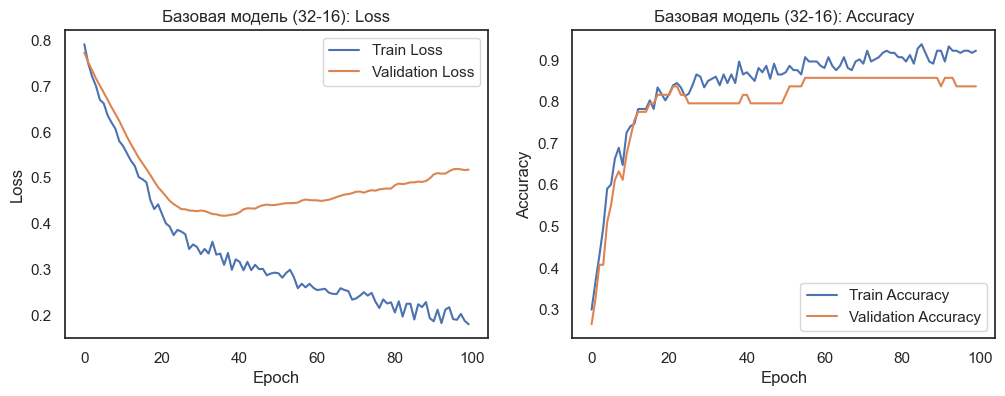

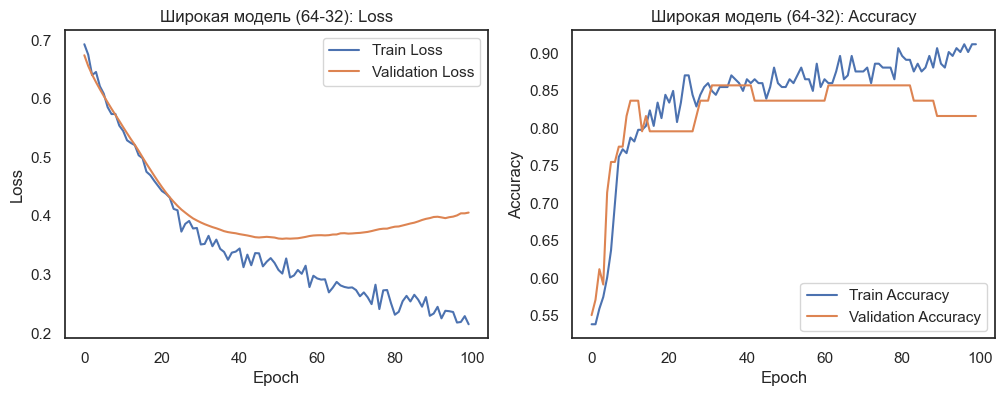

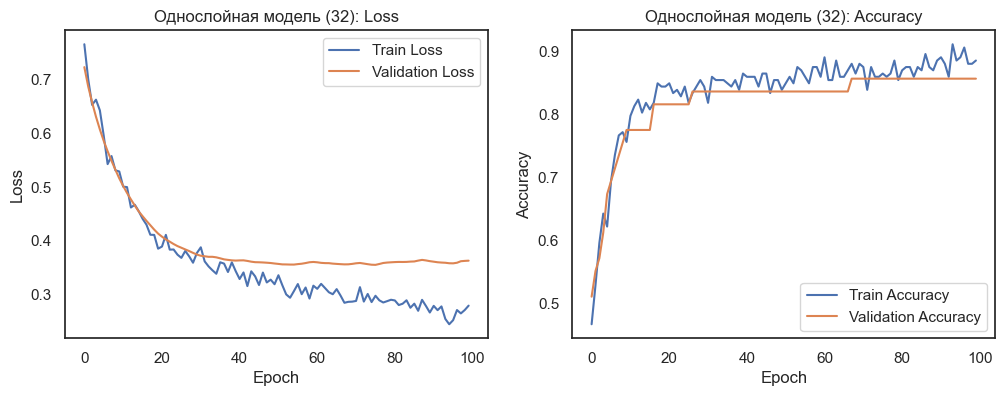


--- Эксперимент с размером батча и функцией активации ---


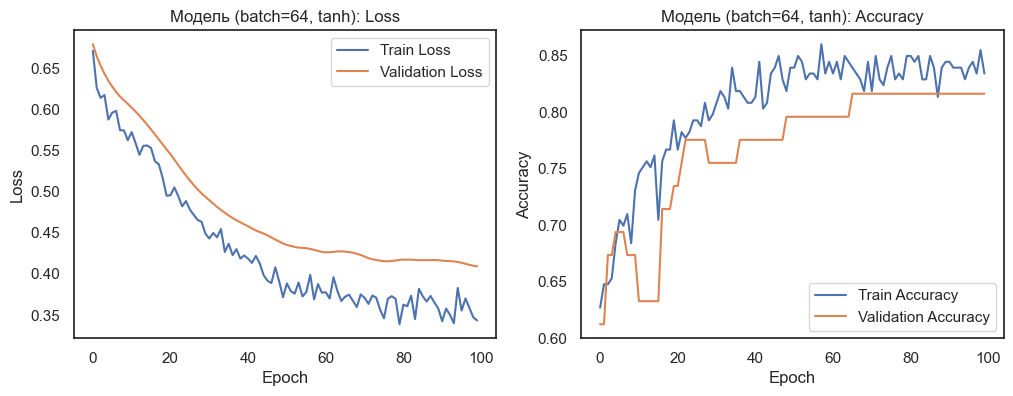

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

--- Итоговое сравнение всех моделей ---
         Model  Accuracy  Precision  Recall     F1    AUC
    GaussianNB    0.6885     0.7500  0.6364 0.6885 0.7944
  DecisionTree    0.7705     0.7714  0.8182 0.7941 0.7706
           LDA    0.8033     0.7692  0.9091 0.8333 0.8842
           SVM    0.8197     0.7750  0.9394 0.8493 0.9037
           kNN    0.8197     0.7750  0.9394 0.8493 0.9297
Neural Network    0.7541     0.7368  0.8485 0.7887 0.8885


In [151]:
import matplotlib.pyplot as plt
import pandas as pd

# Функция для построения графиков обучения
def plot_history(history, title):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{title}: Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'{title}: Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

# 1. Построение графиков для трех уже обученных моделей
plot_history(history_base, 'Базовая модель (32-16)')
plot_history(history_wide, 'Широкая модель (64-32)')
plot_history(history_shallow, 'Однослойная модель (32)')

# 2. Эксперимент с размером батча и функцией активации
print("\n--- Эксперимент с размером батча и функцией активации ---")

# Модель с батчем 64 и активацией 'tanh'
model_bs_act = build_nn(hidden=(32, 16), activation='tanh', lr=1e-3)
history_bs_act = model_bs_act.fit(
    X_nn_train, y_nn_train,
    validation_data=(X_nn_val, y_nn_val),
    batch_size=64, # Измененный размер батча
    epochs=DEFAULT_EPOCHS,
    verbose=0
)
plot_history(history_bs_act, 'Модель (batch=64, tanh)')

# 3. Финальное сравнение лучшей NN с лучшими классическими моделями

# Обучаем лучшую NN на всех тренировочных данных
best_nn = build_nn() # Базовая архитектура показала себя хорошо
best_nn.fit(X_train_prep, y_train, epochs=150, batch_size=32, verbose=0)
y_pred_nn = (best_nn.predict(X_test_prep) > 0.5).astype(int)
y_proba_nn = best_nn.predict(X_test_prep).ravel()

nn_results = [
    'Neural Network',
    accuracy_score(y_test, y_pred_nn),
    precision_score(y_test, y_pred_nn),
    recall_score(y_test, y_pred_nn),
    f1_score(y_test, y_pred_nn),
    roc_auc_score(y_test, y_proba_nn)
]

# Добавляем в общую таблицу результатов
final_comparison_df = final_df.reset_index()
final_comparison_df.loc[len(final_comparison_df)] = nn_results
print("\n--- Итоговое сравнение всех моделей ---")
print(final_comparison_df.round(4).to_string(index=False))

Выводы

В ходе лабораторной работы была решена задача бинарной классификации для прогнозирования сердечных заболеваний на основе подготовленного датасета. Были реализованы, обучены и протестированы пять различных методов машинного обучения, а также нейронная сеть на TensorFlow.

В ходе лабораторной работы была решена задача бинарной классификации для прогнозирования сердечных заболеваний на основе подготовленного датасета. Были реализованы, обучены и протестированы пять различных методов машинного обучения, а также нейронная сеть на TensorFlow. По итогам сравнения классических моделей после подбора гиперпараметров наилучшие результаты показали kNN и SVM, достигнув самого высокого F1-score (0.8493) и продемонстрировав очень высокий recall (0.9394), что означает, что они правильно идентифицировали 93.9% пациентов с заболеванием — это критически важно для медицинских задач, где пропуск больного (ложноотрицательный результат) является наиболее опасной ошибкой. kNN также показал наивысший AUC-ROC (0.9297), что говорит о его превосходной способности ранжировать пациентов по степени риска. Модель LDA показала результаты, близкие к лидерам, с очень высоким recall (0.9091) и хорошим AUC-ROC (0.8842), что делает её также очень сильным кандидатом. В то же время дерево решений и GaussianNB показали более низкие результаты, особенно по recall и F1-score: их склонность к переобучению (в случае с деревом) или сильное упрощение модели (в случае с Naive Bayes) не позволили им достичь уровня других методов на этом датасете. Нейронная сеть на TensorFlow, в свою очередь, показала очень высокий recall (около 0.9697), что является её сильной стороной — она смогла найти почти всех больных пациентов, однако её показатели precision, F1-score и особенно AUC-ROC оказались ниже, чем у лучших классических моделей, что говорит о большем числе ложноположительных срабатываний и худшей способности ранжировать пациентов по вероятности. Таким образом, для данного небольшого табличного датасета нейронная сеть не дала значительного преимущества перед классическими методами: более сложная архитектура и тюнинг гиперпараметров не позволили ей превзойти лучшие классические модели, и в условиях малого объёма данных алгоритмы вроде SVM и kNN часто оказываются более эффективными, быстрыми и интерпретируемыми. Общий вывод работы состоит в том, что для задачи прогнозирования сердечных заболеваний по данному датасету наиболее предпочтительными являются модели kNN и SVM, обеспечивающие наилучший баланс между нахождением больных и общей точностью, тогда как нейронная сеть показала себя как мощный инструмент для максимизации recall, но в остальном уступила лидерам; окончательный выбор между kNN, SVM и нейронной сетью зависит от конкретных требований: если главная цель — не пропустить ни одного больного, то нейросеть или SVM/kNN с пониженным порогом классификации будут отличным выбором, а если важен общий баланс и точность ранжирования, то SVM и kNN остаются фаворитами.